In [33]:
from pathlib import Path
import jax
import jax.numpy as jnp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive
import arviz as az

import arviz_plots as azp
import arviz_base as azb
import arviz_stats as azs
import xarray as xr

from numpyro.infer import SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoNormal
import numpyro.optim as optim
import time

In [20]:
numpyro.set_host_device_count(4)
sns.set_theme(style="whitegrid")
azp.style.use("arviz-variat")

In [3]:
processed_dir = Path("data/processed")
episodes_df = pd.read_csv(processed_dir / "episodes.csv")
weekly_grid_df = pd.read_csv(processed_dir / "weekly_grid.csv")

episodes_df = episodes_df.sort_values("episode_id").reset_index(drop=True)
episodes_df["ep_idx"] = np.arange(len(episodes_df))

weekly_grid_df = weekly_grid_df.merge(
    episodes_df[["episode_id", "ep_idx"]], on="episode_id", how="left"
).sort_values(["ep_idx", "t"]).reset_index(drop=True)

age_mean, age_std = episodes_df["age"].mean(), episodes_df["age"].std()
dist_mean, dist_std = episodes_df["distance_km"].mean(), episodes_df["distance_km"].std()

model_data = {
    "N_episodes": len(episodes_df),
    "age_z": jnp.asarray((episodes_df["age"] - age_mean) / age_std, dtype=jnp.float32),
    "dist_z": jnp.asarray((episodes_df["distance_km"] - dist_mean) / dist_std, dtype=jnp.float32),
    "promo_friends": jnp.asarray(episodes_df["promo_friends"], dtype=jnp.float32),
    "partners_company": jnp.asarray(episodes_df["partners_company"], dtype=jnp.float32),
    "group_affinity": jnp.asarray(episodes_df["group_affinity"], dtype=jnp.float32),
    "is_returning": jnp.asarray(episodes_df["is_returning"], dtype=jnp.float32),
    "ep_idx": jnp.asarray(weekly_grid_df["ep_idx"], dtype=jnp.int32),
    "t": jnp.asarray(weekly_grid_df["t"], dtype=jnp.float32),
    "visits_obs": jnp.asarray(weekly_grid_df["visits"], dtype=jnp.int32),
}

print(f"Data ready to model: {model_data['N_episodes']} episodes, {len(model_data['t'])} weekly observations")

Data ready to model: 556 episodes, 21224 weekly observations


In [5]:
def gym_habit_model(data, include_obs=True):
    N_ep = data["N_episodes"]

    mu_lambda = numpyro.sample("mu_lambda", dist.Normal(jnp.log(2.5), 0.4))
    beta_lambda_dist = numpyro.sample("beta_lambda_dist", dist.Normal(0.0, 0.4))
    beta_lambda_group = numpyro.sample("beta_lambda_group", dist.Normal(0.0, 0.5))
    sigma_lambda = numpyro.sample("sigma_lambda", dist.HalfNormal(0.4))

    mu_tau = numpyro.sample("mu_tau", dist.Normal(jnp.log(16.0), 0.5))
    beta_tau_dist = numpyro.sample("beta_tau_dist", dist.Normal(0.0, 0.5))
    beta_tau_friends = numpyro.sample("beta_tau_friends", dist.Normal(0.0, 0.5))
    beta_tau_group = numpyro.sample("beta_tau_group", dist.Normal(0.0, 0.6))
    beta_tau_partner = numpyro.sample("beta_tau_partner", dist.Normal(0.0, 0.5))
    beta_tau_age = numpyro.sample("beta_tau_age", dist.Normal(0.0, 0.4))
    beta_tau_returning = numpyro.sample("beta_tau_returning", dist.Normal(0.0, 0.4))
    sigma_tau = numpyro.sample("sigma_tau", dist.HalfNormal(0.5))

    mu_gamma = numpyro.sample("mu_gamma", dist.Normal(jnp.log(0.35), 0.5))
    beta_gamma_group = numpyro.sample("beta_gamma_group", dist.Normal(0.0, 0.5))
    beta_gamma_friends = numpyro.sample("beta_gamma_friends", dist.Normal(0.0, 0.5))
    sigma_gamma = numpyro.sample("sigma_gamma", dist.HalfNormal(0.5))

    vacation_prob = numpyro.sample("vacation_prob", dist.Beta(1.5, 18.0))

    with numpyro.plate("episodes", N_ep):
        z_lambda = numpyro.sample("z_lambda", dist.Normal(0.0, 1.0))
        z_tau = numpyro.sample("z_tau", dist.Normal(0.0, 1.0))
        z_gamma = numpyro.sample("z_gamma", dist.Normal(0.0, 1.0))

        log_lambda_base = (
            mu_lambda
            + beta_lambda_dist * data["dist_z"]
            + beta_lambda_group * data["group_affinity"]
            + sigma_lambda * z_lambda
        )

        log_tau = (
            mu_tau
            + beta_tau_dist * data["dist_z"]
            + beta_tau_friends * data["promo_friends"]
            + beta_tau_group * data["group_affinity"]
            + beta_tau_partner * data["partners_company"]
            + beta_tau_age * data["age_z"]
            + beta_tau_returning * data["is_returning"]
            + sigma_tau * z_tau
        )

        log_gamma = (
            mu_gamma
            + beta_gamma_group * data["group_affinity"]
            + beta_gamma_friends * data["promo_friends"]
            + sigma_gamma * z_gamma
        )

        lambda_base = numpyro.deterministic("lambda_base", jnp.exp(log_lambda_base))
        tau = numpyro.deterministic("tau", jnp.clip(jnp.exp(log_tau), 1.0, 250.0))
        gamma = numpyro.deterministic("gamma", jnp.clip(jnp.exp(log_gamma), 0.02, 5.0))

    ep_i = data["ep_idx"]
    t_week = data["t"]

    exponent = jnp.clip(gamma[ep_i] * (t_week - tau[ep_i]), -20.0, 20.0)
    lam_t = lambda_base[ep_i] / (1.0 + jnp.exp(exponent))

    obs_val = data["visits_obs"] if include_obs else None
    numpyro.sample(
        "visits",
        dist.ZeroInflatedPoisson(gate=vacation_prob, rate=lam_t),
        obs=obs_val,
    )

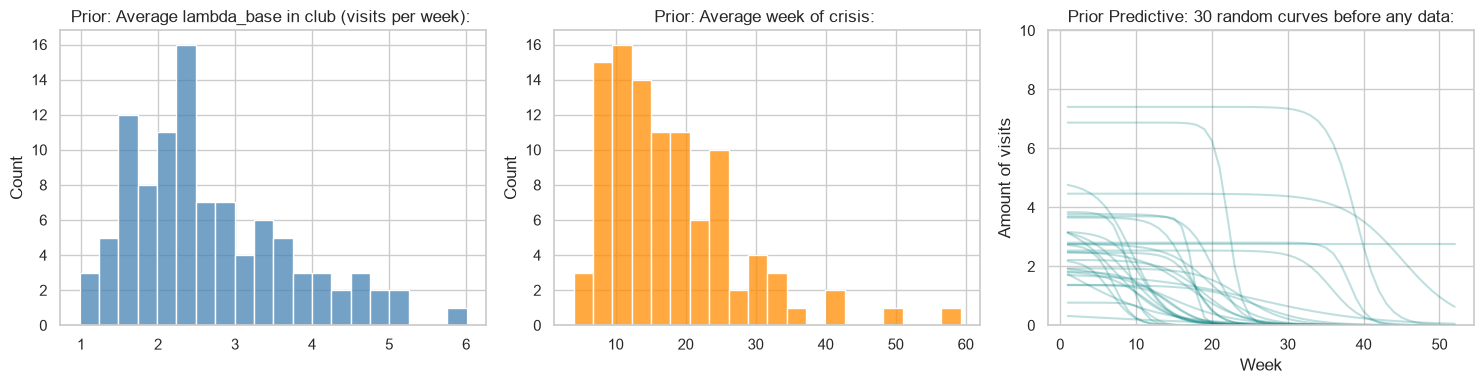

In [8]:
prior_predictive = Predictive(gym_habit_model, num_samples=100)
prior_samples = prior_predictive(jax.random.PRNGKey(42), data=model_data, include_obs=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(np.exp(prior_samples["mu_lambda"]), bins=20, color="steelblue", ax=axes[0])
axes[0].set_title("Prior: Average lambda_base in club (visits per week): ")

sns.histplot(np.exp(prior_samples["mu_tau"]), bins=20, color="darkorange", ax=axes[1])
axes[1].set_title("Prior: Average week of crisis: ")

weeks_grid = np.arange(1, 53)
for s in range(30):
    lb = float(prior_samples["lambda_base"][s, 0])
    t0 = float(prior_samples["tau"][s, 0])
    gm = float(prior_samples["gamma"][s, 0])
    curve = lb / (1.0 + np.exp(np.clip(gm * (weeks_grid - t0), -20, 20)))
    axes[2].plot(weeks_grid, curve, color="teal", alpha=0.25)

axes[2].set_title("Prior Predictive: 30 random curves before any data:")
axes[2].set_xlabel("Week")
axes[2].set_ylabel("Amount of visits")
axes[2].set_ylim(0, 10)

plt.tight_layout()
plt.show()

In [10]:
nuts_kernel = NUTS(gym_habit_model, target_accept_prob=0.85)
mcmc = MCMC(
    nuts_kernel,
    num_warmup=400,
    num_samples=400,
    num_chains=4,
    progress_bar=True
)

mcmc.run(jax.random.PRNGKey(123), data=model_data, include_obs=True)
idata = az.from_numpyro(mcmc)

global_vars = [
    "mu_lambda", "beta_lambda_dist", "beta_lambda_group", "sigma_lambda",
    "mu_tau", "beta_tau_dist", "beta_tau_friends", "beta_tau_group",
    "beta_tau_partner", "beta_tau_age", "beta_tau_returning", "sigma_tau",
    "mu_gamma", "beta_gamma_group", "beta_gamma_friends", "sigma_gamma",
    "vacation_prob",
]

summary_df = az.summary(idata, var_names=global_vars, ci_prob=0.90)
display(summary_df)

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

,mean,sd,eti90_lb,eti90_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_lambda,0.937,0.0211,0.9,0.97,577,666,1.00,0.00088,0.00046
beta_lambda_dist,-0.109,0.0187,-0.14,-0.08,631,934,1.00,0.00075,0.00041
beta_lambda_group,0.196,0.057,0.1,0.29,476,661,1.00,0.0026,0.0015
sigma_lambda,0.295,0.0141,0.27,0.32,470,630,1.01,0.00065,0.00037
mu_tau,2.934,0.039,2.9,3,130,239,1.02,0.0034,0.0012
beta_tau_dist,-0.343,0.03,-0.39,-0.3,275,465,1.02,0.0018,0.00086
beta_tau_friends,0.353,0.054,0.27,0.44,164,321,1.02,0.0042,0.0018
beta_tau_group,0.43,0.089,0.28,0.58,285,504,1.02,0.0052,0.0027
beta_tau_partner,0.126,0.053,0.041,0.21,183,342,1.01,0.0039,0.0016
beta_tau_age,0.161,0.025,0.12,0.2,242,375,1.01,0.0016,0.00084


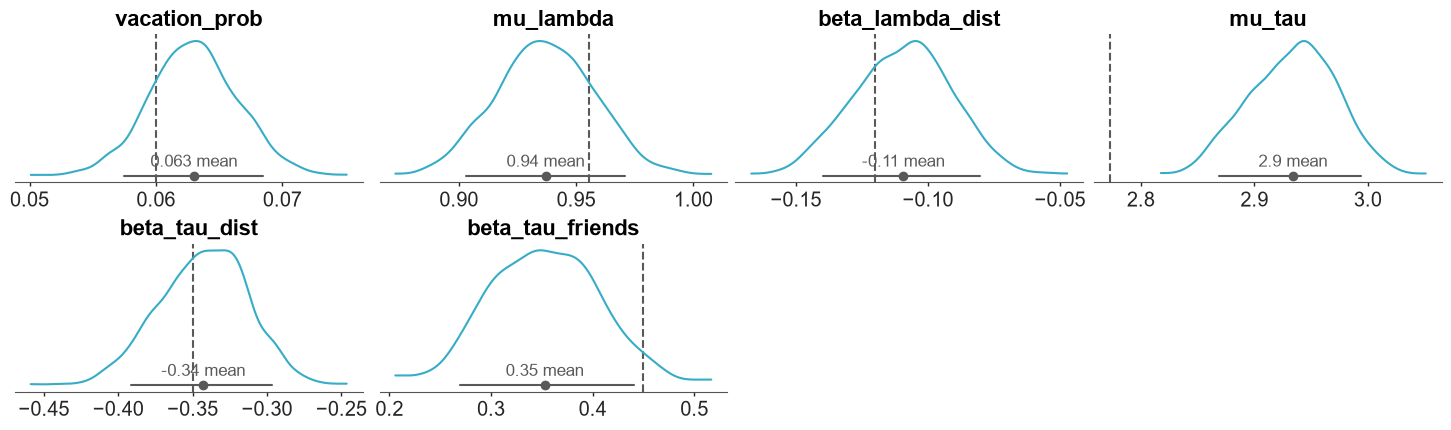

In [23]:
TRUE_PARAMS_FLAT = {
    "vacation_prob": 0.06,
    "mu_lambda": np.log(2.6),
    "beta_lambda_dist": -0.12,
    "mu_tau": np.log(16.0),
    "beta_tau_dist": -0.35,
    "beta_tau_friends": 0.45,
}

pc = azp.plot_dist(
    idata,
    var_names=list(TRUE_PARAMS_FLAT.keys()),
)

azp.add_lines(
    pc,
    values=xr.Dataset(TRUE_PARAMS_FLAT),
    color="black",
    linestyle="--"
)

pc.show()

In [34]:
start_time = time.time()

guide = AutoNormal(gym_habit_model)

optimizer = optim.Adam(step_size=0.01)
svi = SVI(gym_habit_model, guide, optimizer, loss=Trace_ELBO())

svi_result = svi.run(jax.random.PRNGKey(42), num_steps=5000, data=model_data, include_obs=True)

svi_samples = Predictive(guide, params=svi_result.params, num_samples=1000)(
    jax.random.PRNGKey(1), data=model_data, include_obs=True
)

svi_time = time.time() - start_time
print(f"SVI training finished in: {svi_time:.2f} seconds")

posterior_dict = {k: np.expand_dims(np.asarray(v), 0) for k, v in svi_samples.items()}
idata_svi = azb.from_dict({"posterior": posterior_dict})

summary_svi = azs.summary(
    idata_svi,
    var_names=["mu_lambda", "mu_tau", "vacation_prob", "beta_tau_friends"],
    ci_prob=0.90
)
display(summary_svi)

100%|██████████| 5000/5000 [00:23<00:00, 217.20it/s, init loss: 312104.1562, avg. loss [4751-5000]: 29433.1172]


SVI training finished in: 29.63 seconds


,mean,sd,eti90_lb,eti90_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_lambda,0.9389,0.0066,0.93,0.95,914,772,nan,0.00022,0.00016
mu_tau,2.9825,0.0045,3,3,991,910,nan,0.00014,0.0001
vacation_prob,0.0654,0.0031,0.061,0.071,956,946,nan,0.0001,7.2e-05
beta_tau_friends,0.3463,0.0064,0.34,0.36,861,783,nan,0.00022,0.00014
